# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 0
rng = np.random.default_rng(SEED)

DATA_PATH = Path("data/spambase.csv")
EXPECTED_SHA256 = "b1ef93de71f97714d3d7d4f58fc9f718da7bbc8ac8a150eff2778616a8097b12"


def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()


actual_sha256 = sha256_of(DATA_PATH)
assert actual_sha256 == EXPECTED_SHA256, f"{DATA_PATH} does not match data/README.md: {actual_sha256}"
print(f"{DATA_PATH} verified against data/README.md: {actual_sha256}")

data\spambase.csv verified against data/README.md: b1ef93de71f97714d3d7d4f58fc9f718da7bbc8ac8a150eff2778616a8097b12


## Question

Given the content of a single email, what is P(spam = 1), estimated the moment the email is received, and should the filter block or deliver it? The decision is the provider's spam filter choosing to block or deliver; the costlier mistake is delivering spam/phishing (a false negative), not blocking a legitimate email (a false positive) (see Decision).

![Layer diagram](fig/layers.png)

## Data

Source: UCI Machine Learning Repository, "Spambase" dataset (DOI 10.24432/C53G6X), donated by Hopkins, Reeber, Forman, and Suermondt. Unit of observation: one email, represented by 57 numeric content features (48 word-frequency, 6 character-frequency, 3 capital-letter-run-length) plus a spam/not-spam label. Sample size: 4,601 emails. Collected circa 1999 at Hewlett-Packard Labs: spam came from the postmaster and individuals who had filed spam, non-spam came from an employee's work and personal email. No finer timestamp than "circa 1999" is published, so there is no later time period to hold out (see Split).

Measurement gap: the label is a 1999 human call on corporate email, not a measurement of modern phishing technique (spoofed domains, malicious links, credential-harvesting language). That gap is bias, not noise — it will not shrink with more rows of this same data, only with different features. Released under CC BY 4.0 and republished in this fork's `data` GitHub release; see `data/README.md` for the SHA-256 checked in Setup.

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

If the terms do not let you republish the files, there is no release: run the download command in `data/README.md` instead.

In [2]:
COLUMN_NAMES = [
    "word_freq_make", "word_freq_address", "word_freq_all", "word_freq_3d", "word_freq_our",
    "word_freq_over", "word_freq_remove", "word_freq_internet", "word_freq_order", "word_freq_mail",
    "word_freq_receive", "word_freq_will", "word_freq_people", "word_freq_report", "word_freq_addresses",
    "word_freq_free", "word_freq_business", "word_freq_email", "word_freq_you", "word_freq_credit",
    "word_freq_your", "word_freq_font", "word_freq_000", "word_freq_money", "word_freq_hp",
    "word_freq_hpl", "word_freq_george", "word_freq_650", "word_freq_lab", "word_freq_labs",
    "word_freq_telnet", "word_freq_857", "word_freq_data", "word_freq_415", "word_freq_85",
    "word_freq_technology", "word_freq_1999", "word_freq_parts", "word_freq_pm", "word_freq_direct",
    "word_freq_cs", "word_freq_meeting", "word_freq_original", "word_freq_project", "word_freq_re",
    "word_freq_edu", "word_freq_table", "word_freq_conference",
    "char_freq_semicolon", "char_freq_paren", "char_freq_bracket", "char_freq_bang",
    "char_freq_dollar", "char_freq_hash",
    "capital_run_length_average", "capital_run_length_longest", "capital_run_length_total",
    "spam",
]

df = pd.read_csv(DATA_PATH, header=None, names=COLUMN_NAMES)
print(df.shape)
df.describe().T[["mean", "std", "min", "max"]].round(3)

(4601, 58)


,mean,std,min,max
word_freq_make,0.105,0.305,0.0,4.540
word_freq_address,0.213,1.291,0.0,14.280
word_freq_all,0.281,0.504,0.0,5.100
word_freq_3d,0.065,1.395,0.0,42.810
word_freq_our,0.312,0.673,0.0,10.000
word_freq_over,0.096,0.274,0.0,5.880
word_freq_remove,0.114,0.391,0.0,7.270
word_freq_internet,0.105,0.401,0.0,11.110
word_freq_order,0.090,0.279,0.0,5.260
word_freq_mail,0.239,0.645,0.0,18.180


## Split

This is cross-sectional data (see Data): no email carries a published timestamp finer than "circa 1999", so there is no later time period to hold out by date. The split is instead a random stratified 80/20 train/test split; the seed and fraction are recorded in `decisions.md`. Fitting, scaling, and feature use below touch only the training rows.

In [3]:
X = df.drop(columns="spam")
y = df["spam"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f"train: {len(X_train)} rows ({y_train.mean():.3f} spam rate)")
print(f"test:  {len(X_test)} rows ({y_test.mean():.3f} spam rate)")

train: 3680 rows (0.394 spam rate)
test:  921 rows (0.394 spam rate)


## Baseline

The decision costs false negatives (delivering spam/phishing) more than false positives (blocking a legitimate email) — see Decision for the assumed ratio. The baseline is the majority-class rule: always deliver (predict "not spam" for every email, since not-spam is the majority class). It is scored on the held-out test set in the same cost units as the model below, not accuracy.

In [4]:
COST_FALSE_NEGATIVE = 5.0  # delivering spam/phishing that should have been blocked
COST_FALSE_POSITIVE = 1.0  # blocking a legitimate email


def decision_cost(y_true, y_pred):
    fn = ((y_true == 1) & (y_pred == 0)).sum()
    fp = ((y_true == 0) & (y_pred == 1)).sum()
    return fn * COST_FALSE_NEGATIVE + fp * COST_FALSE_POSITIVE


baseline_pred = np.zeros(len(y_test), dtype=int)  # always deliver
baseline_cost = decision_cost(y_test.values, baseline_pred)
print(
    f"Baseline (always deliver) cost on test set: {baseline_cost:.0f} units "
    f"({baseline_cost / len(y_test):.3f} per email)"
)

Baseline (always deliver) cost on test set: 1815 units (1.971 per email)


## Model

Logistic regression on standardized features: for email $i$ with standardized content features $x_{i,1}, \dots, x_{i,57}$,

$$\log\left(\frac{p_i}{1-p_i}\right) = \beta_0 + \sum_{j=1}^{57} \beta_j x_{i,j}, \qquad p_i = P(\text{spam}=1 \mid x_i)$$

$\beta_0$ is the log-odds of spam for an email at the average value of every feature. Each $\beta_j$ is the change in log-odds of spam per one-standard-deviation increase in feature $j$, holding the others fixed. The assumption trusted least is additivity in the log-odds: word frequencies plausibly interact (the word "free" means something different next to "!!!" and a dollar sign than it does alone), and a linear-in-log-odds model cannot represent that. Fit on the training rows only (scaler included); scored on the held-out test set in the same cost units as the baseline, using the decision rule from the Decision section.

In [5]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=2000, random_state=SEED)
model.fit(X_train_s, y_train)

p_test = model.predict_proba(X_test_s)[:, 1]

THRESHOLD = COST_FALSE_POSITIVE / (COST_FALSE_POSITIVE + COST_FALSE_NEGATIVE)
model_pred = (p_test >= THRESHOLD).astype(int)
model_cost = decision_cost(y_test.values, model_pred)

print(f"Decision threshold (cost-ratio optimal): {THRESHOLD:.3f}")
print(
    f"Logistic model cost on test set: {model_cost:.0f} units "
    f"({model_cost / len(y_test):.3f} per email)"
)
print(f"Cost reduction vs. baseline: {(1 - model_cost / baseline_cost):.1%}")

Decision threshold (cost-ratio optimal): 0.167
Logistic model cost on test set: 134 units (0.145 per email)
Cost reduction vs. baseline: 92.6%


## Simulation check

Draw synthetic labels from the fitted model using the real training features: $\tilde y_i \sim \text{Bernoulli}(\hat p_i)$, where $\hat p_i$ comes from the model just fit. Refit the same logistic regression on $(X_{\text{train}}, \tilde y)$ and compare the recovered coefficients to the ones the real labels gave. If the fitting procedure is sound, the two should sit on the diagonal.

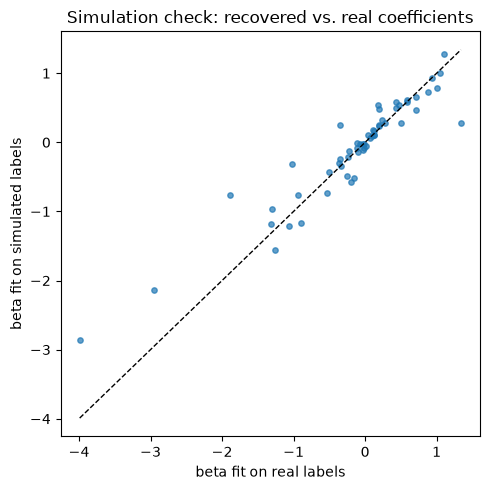

Correlation between real-label and simulated-label coefficients: 0.938


In [6]:
p_sim_source = model.predict_proba(X_train_s)[:, 1]
y_sim = rng.binomial(1, p_sim_source)

sim_model = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_train_s, y_sim)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(model.coef_[0], sim_model.coef_[0], s=15, alpha=0.7)
lims = [
    min(model.coef_[0].min(), sim_model.coef_[0].min()),
    max(model.coef_[0].max(), sim_model.coef_[0].max()),
]
ax.plot(lims, lims, "k--", linewidth=1)
ax.set_xlabel("beta fit on real labels")
ax.set_ylabel("beta fit on simulated labels")
ax.set_title("Simulation check: recovered vs. real coefficients")
fig.tight_layout()
fig.savefig("fig/simulation_check.png", dpi=150)
plt.show()

corr = np.corrcoef(model.coef_[0], sim_model.coef_[0])[0, 1]
print(f"Correlation between real-label and simulated-label coefficients: {corr:.3f}")

## Residuals and calibration

Residual here is $y_i - \hat p_i$. There is no time axis (see Split), so residuals are plotted against the prediction itself, and $\hat p$ is binned into deciles to check calibration: in each decile, the mean predicted probability should match the observed spam rate.

                     mean_p_hat  observed_rate   n
bin                                               
(-0.001, 2.47e-06]        0.000          0.000  93
(2.47e-06, 0.00105]       0.000          0.000  92
(0.00105, 0.0134]         0.005          0.022  92
(0.0134, 0.0571]          0.032          0.022  92
(0.0571, 0.162]           0.109          0.033  92
(0.162, 0.45]             0.277          0.217  92
(0.45, 0.851]             0.689          0.837  92
(0.851, 0.973]            0.921          0.913  92
(0.973, 0.998]            0.991          0.968  93
(0.998, 1.0]              1.000          0.934  91


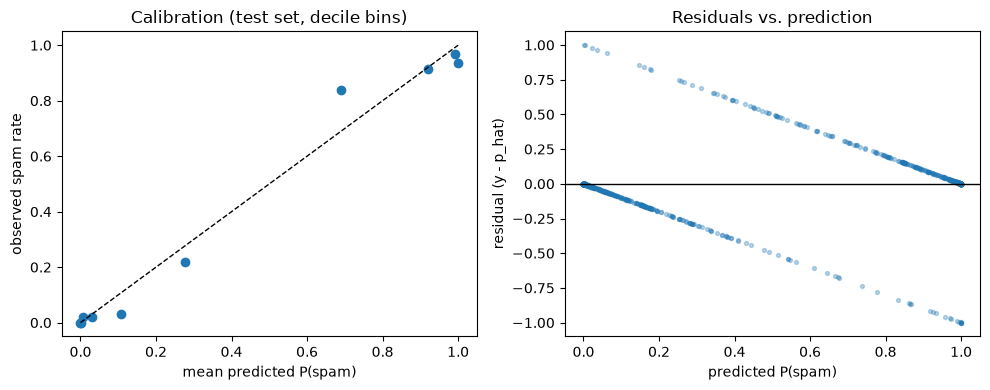

In [7]:
bins = pd.qcut(p_test, 10, duplicates="drop")
calib = (
    pd.DataFrame({"p_hat": p_test, "y": y_test.values, "bin": bins})
    .groupby("bin", observed=True)
    .agg(mean_p_hat=("p_hat", "mean"), observed_rate=("y", "mean"), n=("y", "size"))
)
print(calib.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].scatter(calib["mean_p_hat"], calib["observed_rate"])
axes[0].set_xlabel("mean predicted P(spam)")
axes[0].set_ylabel("observed spam rate")
axes[0].set_title("Calibration (test set, decile bins)")

residuals = y_test.values - p_test
axes[1].scatter(p_test, residuals, s=8, alpha=0.3)
axes[1].axhline(0, color="k", linewidth=1)
axes[1].set_xlabel("predicted P(spam)")
axes[1].set_ylabel("residual (y - p_hat)")
axes[1].set_title("Residuals vs. prediction")

fig.tight_layout()
fig.savefig("fig/calibration.png", dpi=150)
plt.show()

## Decision

Rule: compute $\hat p = P(\text{spam}=1 \mid x)$ from the model; block the email if $\hat p \ge t$, deliver otherwise. The cost-minimizing threshold is $t = c_{FP} / (c_{FP} + c_{FN})$; with the assumed $c_{FN}=5$, $c_{FP}=1$ (see Baseline), $t \approx 0.167$. These costs are illustrative, not the provider's actual published ratio — `decisions.md` records them as the number to revisit once a real ratio is known.

                    threshold  block_rate  cost_per_email
cost_ratio (FN/FP)                                       
1                       0.500       0.391           0.068
2                       0.333       0.431           0.083
3                       0.250       0.459           0.104
5                       0.167       0.494           0.145
8                       0.111       0.547           0.202
12                      0.077       0.570           0.246
20                      0.048       0.618           0.315


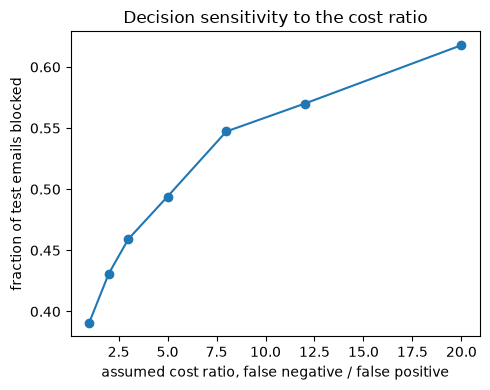


Baseline:        1.971 cost units/email
Logistic model:  0.145 cost units/email
Remaining gap to a perfect classifier: 0.145 cost units/email -- the most a better model could be worth at this assumed cost ratio.


In [8]:
def cost_at_ratio(ratio):
    t = 1.0 / (1.0 + ratio)
    pred = (p_test >= t).astype(int)
    fn = ((y_test.values == 1) & (pred == 0)).sum()
    fp = ((y_test.values == 0) & (pred == 1)).sum()
    cost = fn * ratio + fp * 1.0  # cost units where c_FP = 1
    return t, pred.mean(), cost / len(y_test)


ratios = [1, 2, 3, 5, 8, 12, 20]
rows = [cost_at_ratio(r) for r in ratios]
sweep = pd.DataFrame(rows, columns=["threshold", "block_rate", "cost_per_email"], index=ratios)
sweep.index.name = "cost_ratio (FN/FP)"
print(sweep.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(sweep.index, sweep["block_rate"], marker="o")
ax.set_xlabel("assumed cost ratio, false negative / false positive")
ax.set_ylabel("fraction of test emails blocked")
ax.set_title("Decision sensitivity to the cost ratio")
fig.tight_layout()
fig.savefig("fig/decision_sensitivity.png", dpi=150)
plt.show()

oracle_cost_per_email = 0.0  # a perfect classifier makes no FN/FP
model_cost_per_email = model_cost / len(y_test)
baseline_cost_per_email = baseline_cost / len(y_test)
print(f"\nBaseline:        {baseline_cost_per_email:.3f} cost units/email")
print(f"Logistic model:  {model_cost_per_email:.3f} cost units/email")
print(
    f"Remaining gap to a perfect classifier: {model_cost_per_email - oracle_cost_per_email:.3f} "
    f"cost units/email -- the most a better model could be worth at this assumed cost ratio."
)

Across the whole cost-ratio sweep (1:1 through 20:1) the model beats the always-deliver baseline outright; there is no ratio in this range where it only ties, because the baseline cost grows linearly with the ratio (it never blocks anything) while the model keeps most of its false negatives near the 39% base rate.

## Limits

Do not trust this model as a modern phishing filter: Spambase is pre-2000 corporate email at one company, and today's phishing relies on signals the 57 features cannot see at all (spoofed sender domains, malicious URLs, attachment payloads, credential-harvesting page content). The feature set was already engineered by the dataset's creators; no feature-leakage or feature-selection search happened here, but also no raw email text was available to re-derive features from.

Assumed: the cost ratio $c_{FN}/c_{FP} = 5$ is illustrative, chosen to reflect "a missed phishing email is worse than a misfiled newsletter," not measured from a real provider's complaint or incident data. The Decision section's sensitivity sweep shows this choice changes the block rate and cost substantially, so it is the single most consequential unverified assumption in the project. The linearity-in-log-odds assumption (see Model) is the second: interaction effects between word frequencies are plausible and untested here.

With more time or data: get a real cost ratio from an email provider or a published incident-cost study; add a 2020s-era phishing/spam corpus (e.g. a URL- or header-based feature set) to check whether these coefficients generalize past 1999 corporate email; and test for feature interactions (e.g. an L2-penalized model with explicit interaction terms, or a tree-based model) against this linear baseline.

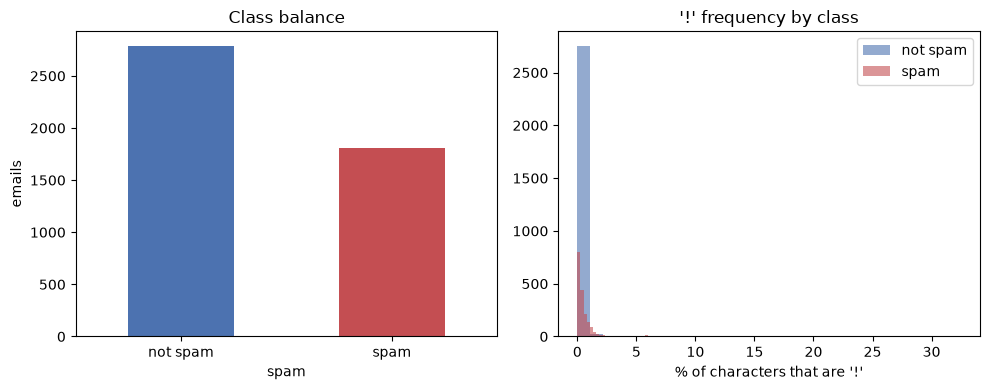

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

df["spam"].map({0: "not spam", 1: "spam"}).value_counts().plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"]
)
axes[0].set_title("Class balance")
axes[0].set_ylabel("emails")
axes[0].tick_params(axis="x", rotation=0)

for label, color in [(0, "#4C72B0"), (1, "#C44E52")]:
    subset = df.loc[df["spam"] == label, "char_freq_bang"]
    axes[1].hist(subset, bins=30, alpha=0.6, label="spam" if label else "not spam", color=color)
axes[1].set_title("'!' frequency by class")
axes[1].set_xlabel("% of characters that are '!'")
axes[1].legend()

fig.tight_layout()
fig.savefig("fig/data_overview.png", dpi=150)
plt.show()

### Uncertainty

Standard errors below come from a nonparametric bootstrap (resample the training rows with replacement, refit, repeat), not a closed-form formula, since the decision rule (threshold on $\hat p$) is itself nonlinear. Each test email's predicted probability also carries a bootstrap standard error — that is its predictive uncertainty.

In [10]:
N_BOOT = 200
boot_coefs = np.zeros((N_BOOT, X_train.shape[1]))
boot_probs = np.zeros((N_BOOT, len(X_test)))

for b in range(N_BOOT):
    idx = rng.integers(0, len(X_train), len(X_train))
    Xb, yb = X_train_s[idx], y_train.values[idx]
    m = LogisticRegression(max_iter=2000, random_state=SEED).fit(Xb, yb)
    boot_coefs[b] = m.coef_[0]
    boot_probs[b] = m.predict_proba(X_test_s)[:, 1]

coef_se = boot_coefs.std(axis=0)
prob_se = boot_probs.std(axis=0)

top5 = np.argsort(-np.abs(model.coef_[0]))[:5]
for i in top5:
    print(f"{X.columns[i]:28s} beta={model.coef_[0][i]:+.3f}  bootstrap SE={coef_se[i]:.3f}")

print(f"\nMedian bootstrap SE of predicted P(spam) on test set: {np.median(prob_se):.3f}")

word_freq_george             beta=-3.990  bootstrap SE=0.330
word_freq_hp                 beta=-2.956  bootstrap SE=0.518
word_freq_cs                 beta=-1.895  bootstrap SE=0.426
capital_run_length_average   beta=+1.339  bootstrap SE=0.669
word_freq_meeting            beta=-1.312  bootstrap SE=0.209

Median bootstrap SE of predicted P(spam) on test set: 0.013


Calibration tracks the diagonal closely through the middle deciles (e.g. mean predicted 0.277 vs. observed 0.217 in the 5th bin) — that spread looks like noise, not a systematic bias, since it is not one-directional. The one place it is not noise: the top decile (predicted p-hat in 0.998-1.0) predicts essentially certain spam but the observed rate there is 0.934, so about 6.6% of the emails the model is most confident about are actually legitimate. The residual-vs-prediction plot shows the same pattern: residuals bunch near zero at both extremes (confident predictions are mostly right) and spread out in the 0.2-0.8 range, where spam and non-spam content genuinely overlap.